<h1>Tiamat</h1>

<h4><i>Bruno Bini Camargo</i></h4>

<h2>Sumário</h2>

01. Introdução
02. Problema e hipótese
03. Descrição do dataset
04. Análise exploratória dos dados
05. Preparação dos dados
06. Separação treino/teste
07. Baseline
08. Pipelines de Machine Learning
09. Otimização com Optuna
10. Comparação dos modelos
11. Análise dos melhores modelos
12. Interpretabilidade
13. Discussão dos resultados
14. Limitações
15. Conclusões e principais aprendizados
16. Descrição do uso de IA neste trabalho
17. Referências

<h2>1- Introdução</h2>

O Enem (Exame Nacional do Ensino Médio), criado em 1998, é uma prova realizada anualmente no Brasil, com o objetivo de avaliar o desempenho dos estudantes ao fim da educação básica. A partir de 2009, passou a ser utilizado como forma de acesso ao ensino superior [1].

As provas envolvem quatro áreas do conhecimento: linguagens, códigos e suas tecnologias; ciências humanas e suas tecnologias; ciências da natureza e suas tecnologias; e matemática e suas tecnologias, o que totaliza 180 questões objetivas. Além disso, o exame inclui ainda uma redação, composta pela produção de um texto dissertativo-argumentativo a partir de uma situação-problema [1].

As notas das questões objetivas do Enem são dadas por meio do TRI (Teoria de Resposta ao Item), um modelo matemático que analisa o padrão de respostas do candidato em relação ao conjunto de questões que formam o exame, priorizando o desempenho que for mais coerente. O TRI qualifica as questões com base em três parâmetros: grau de dificuldade, discriminação e acerto ao acaso (chute) [2]. 
Com as notas calculadas para cada uma das quatro áreas do conhecimento, soma-se a nota atingida pelo candidato na redação e, dividindo essa soma por 5, obtém-se a média total com redação. 

Nesse contexto, a avaliação educacional em larga escala desempenha um papel estratégico ao fornecer diagnósticos sobre a qualidade do ensino e fundamentar o planejamento pedagógico. Os resultados do exame permitem mensurar disparidades entre diferentes dependências administrativas (escolas públicas e privadas), evidenciando o impacto das assimetrias estruturais e de recursos no desempenho escolar.

Além da comparação entre categorias de ensino, destaca-se a dinâmica existente entre as provas objetivas e a prova de redação. Enquanto as questões objetivas testam competências técnicas, raciocínio lógico e domínio conceitual em áreas específicas, a redação exige articulação argumentativa, repertório sociocultural e domínio da norma-padrão. Investigar a correlação entre essas diferentes dimensões de avaliação permite compreender se o desempenho técnico nas áreas objetivas acompanha, de maneira proporcional, a capacidade de produção textual.

Diante do volume e da complexidade dos dados gerados pelo Enem, a aplicação de técnicas de Aprendizado de Máquina surge como uma abordagem promissora para modelar essas relações, como a que será realizada nesse trabalho.

<h2>2- Problema e hipótese</h2>

Diante desse cenário, este estudo investiga em que medida a integração de métricas de posicionamento relativo (rankings estaduais e nacionais) e fatores contextuais (dependência administrativa, localização e volume de participantes) aprimora a precisão de modelos de Machine Learning na predição da média geral, com redação, entre as 500 escolas de maior desempenho no Enem 2025. 

Como hipótese, assume-se que, embora a média final seja predominantemente determinada pelas notas das provas objetivas, a inclusão de variáveis contextuais e de ranqueamento permite aos algoritmos capturar padrões não lineares complexos, reduzindo o erro de estimativa em relação aos modelos fundamentados apenas no desempenho objetivo.

<h2>3- Descrição do dataset e análise exploratória dos dados</h2>

<h3>3.1 - Descrição</h3>

O conjunto de dados analítico é composto por 500 instituições de ensino, selecionadas a partir do topo do ranking nacional de desempenho do Enem 2025. O recorte metodológico delimita a amostra às escolas de maior rendimento acadêmico do país, permitindo investigar a dinâmica preditiva do exame em um contexto de alta proficiência.

Abaixo, transformo os dados do ranking, que estão em uma planilha Excel, para o formato de Data Frame do Python, por meio do módulo pandas. 

In [6]:
import pandas as pd

df = pd.read_excel("Enem_Acompanhamento_de_escolas_2025.xlsx")

df['Estado'] = df['Estado'].str.upper()

df.head().style.hide(axis = 'index')

ID Escola,Escola,Cidade,Estado,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Média nacional (com redação),Administração,Número de participantes
23246871,Ari De Sa Cavalcante - Mario Mamede,Fortaleza,CE,1,1,1,1,1,1,774.580000,801.290000,Privada,32
23246847,Farias Brito Colegio De Aplicacao,Fortaleza,CE,2,2,2,2,2,2,765.130000,793.300000,Privada,30
23246880,Christus Colegio Pre Universitario,Fortaleza,CE,3,3,3,3,3,3,753.580000,779.330000,Privada,34
22144714,Sao Jose Leste,Teresina,PI,1,1,1,1,4,4,743.880000,773.830000,Privada,22
23235543,Ari De Sa Cavalcante - Major Facundo,Fortaleza,CE,4,4,4,4,5,6,737.170000,765.730000,Privada,31


É perceptível que o dataset apresenta 14 variáveis, com dados categóricos e numéricos. 

Por questões de codificação de variáveis categóricas, a variável `Escola` será removida sem perda de informação, visto que o `ID Escola` cumpre a função de identificador único de cada instituição. Além disso, a variável `Cidade` também será desconsiderada para evitar alta cardinalidade no modelo preditivo, mantendo-se a granularidade geográfica no nível de `Estado`.

In [7]:
df = df.drop(columns = ['Escola', 'Cidade'])

df.head().style.hide(axis = 'index')

ID Escola,Estado,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Média nacional (com redação),Administração,Número de participantes
23246871,CE,1,1,1,1,1,1,774.580000,801.290000,Privada,32
23246847,CE,2,2,2,2,2,2,765.130000,793.300000,Privada,30
23246880,CE,3,3,3,3,3,3,753.580000,779.330000,Privada,34
22144714,PI,1,1,1,1,4,4,743.880000,773.830000,Privada,22
23235543,CE,4,4,4,4,5,6,737.170000,765.730000,Privada,31


Em seguida, a próxima etapa a ser realizada é a divisão dos dados em atributos (variáveis preditoras) e target (variável a ser prevista). Neste trabalho, o **target** será a `Média nacional (com redação)`, e os **atributos** serão: `ID Escola`, `Estado`, `Posição municipal (com redação)`, `Posição municipal (objetivas)`, `Posição estadual (com redação)`, `Posição estadual (objetivas)`, `Posição total (com redação)`, `Posição total (objetivas)`, `Média nacional (objetivas)`, `Administração` e `Número de participantes`.

In [7]:
atributos = [
    'ID Escola',
    'Estado',
    'Posição municipal (com redação)',
    'Posição municipal (objetivas)',
    'Posição estadual (com redação)',
    'Posição estadual (objetivas)',
    'Posição total (com redação)',
    'Posição total (objetivas)',
    'Média nacional (objetivas)',
    'Administração',
    'Número de participantes'
]

target = ['Média nacional (com redação)']

X = df[atributos]
y = df[target]

Divididos os dados nesses dois grupos, pode-se seguir à análise exploratória.

<h3>3.2 - Análise exploratória</h3>

Agora será realizada uma **análise exploratória dos dados**, visando compreender a estrutura, distribuições, padrões e relações presentes no dataset, fornecendo embasamento para a escolha e preparação das variáveis no modelo preditivo.

Como o objetivo principal é prever a `Média nacional (com redação)`, é fundamental analisar primeiramente a forma da sua distribuição. Essa análise permite verificar se a variável apresenta comportamento próximo a uma distribuição normal, se há assimetrias pronunciadas ou presença de *outliers* que possam impactar o desempenho dos algoritmos de regressão.

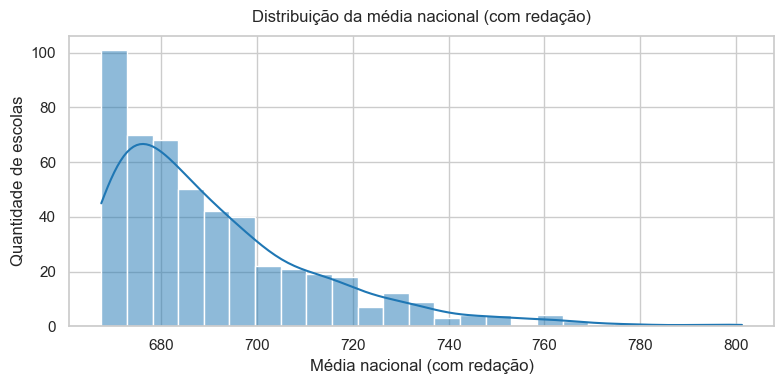

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

target_col = df['Média nacional (com redação)']

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(target_col, kde=True, color='#1f77b4', bins=25, ax=ax)

ax.set_title('Distribuição da média nacional (com redação)', fontsize=12, pad=10)
ax.set_xlabel('Média nacional (com redação)')
ax.set_ylabel('Quantidade de escolas')

plt.tight_layout()
plt.show()

Ao analisar os dados extraídos da coluna, observa-se que a variável apresenta **assimetria à direita**. A maioria das escolas do top 500 concentra-se no intervalo de 670 a 700 pontos, enquanto uma minoria de instituições estende a cauda da distribuição até valores próximos de 800 pontos.

Em seguida, outra análise importante é verificar a relação entre a `Média nacional (objetivas)` (eixo X) e a `Média nacional (com redação)` (eixo Y).

O gráfico de dispersão (*scatter plot*) abaixo tem como objetivo investigar a presença de uma linha de tendência, o nível de dispersão das escolas e a identificação de possíveis *outliers*.

Para quantificar a força e a direção da associação antes da visualização gráfica, utiliza-se o **Coeficiente de Correlação de Pearson ($r$)**, calculado pela fórmula:

$$r = \frac{\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}{\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2 \cdot \sum_{i=1}^{n} (Y_i - \bar{Y})^2}}$$

onde:
* $X_i$ e $Y_i$ representam, respectivamente, a média objetiva e a média com redação da escola $i$
* $\bar{X}$ e $\bar{Y}$ são as médias amostrais dessas variáveis
* $n$ é o total de instituições na amostra ($N = 500$).

O valor de $r$ varia entre $-1$ e $+1$. Um valor próximo de $+1$ indica forte correlação linear positiva. 

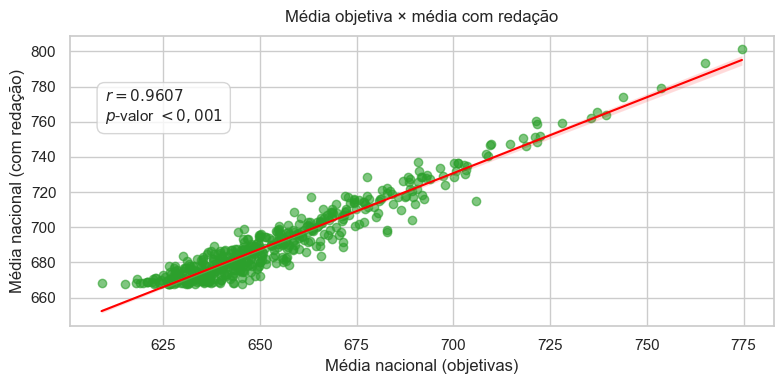

In [13]:
from scipy.stats import pearsonr

x_objetivas = df['Média nacional (objetivas)']
y_target = df['Média nacional (com redação)']

r_valor, p_valor = pearsonr(x_objetivas, y_target)

fig, ax = plt.subplots(figsize=(8, 4))
sns.regplot(
    x=x_objetivas, 
    y=y_target, 
    scatter_kws={'alpha':0.6, 'color':'#2ca02c'}, 
    line_kws={'color':'red', 'linewidth':1.5}, 
    ax=ax
)

texto_r = f'$r = {r_valor:.4f}$\n$p$-valor $< 0,001$'
ax.text(
    0.05, 0.82, texto_r, transform=ax.transAxes, fontsize=11,
    verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='#cccccc')
)

ax.set_title('Média objetiva × média com redação', fontsize=12, pad=10)
ax.set_xlabel('Média nacional (objetivas)')
ax.set_ylabel('Média nacional (com redação)')

plt.tight_layout()
plt.show()

Analisando o gráfico acima, observa-se uma forte tendência ascendente contínua. Conforme a média das provas objetivas aumenta, a média com redação cresce de forma diretamente proporcional, confirmando o caráter predominantemente linear da relação entre as duas variáveis no topo do desempenho. Além disso, a proximidade estreita dos pontos em relação à linha vermelha reflete uma altíssima correlação positiva ($r \approx 0{,}96$), o que indica que o rendimento nas provas objetivas atua como explicativo da nota final.

A pequena dispersão vertical observada ao longo da reta representa a variabilidade residual decorrente do efeito individual da nota de redação: enquanto escolas situadas acima da reta de regressão conseguem "alavancar" sua média final por meio de um bom rendimento discursivo, pontos abaixo da linha representam instituições nas quais a nota de redação reduziu o rendimento médio acumulado nas objetivas. Por fim, nota-se que tanto no extremo superior (médias objetivas acima de 750) quanto no extremo inferior (médias objetivas abaixo de 625), a dispersão se mantém perfeitamente alinhada com a tendência global, sem a presença de outliers decorrentes de erros de medição.

Após constatar a forte correlação entre as provas objetivas e a média final, é interessante investigar como os fatores contextuais e institucionais se comportam ao longo dessa distribuição de desempenho. Nesse sentido, a dependência administrativa apresenta-se como uma dimensão estrutural relevante no cenário educacional brasileiro. A fim de verificar como o comportamento linear observado anteriormente se desdobra entre as redes de ensino, será utilizado um gráfico de caixa (*boxplot*) para comparar a distribuição da `Média nacional (com redação)` entre as escolas privadas e públicas integrantes do top 500. Essa visualização permite analisar se existem diferenças significativas de mediana, amplitude interquartil e teto de notas entre as duas categorias. 

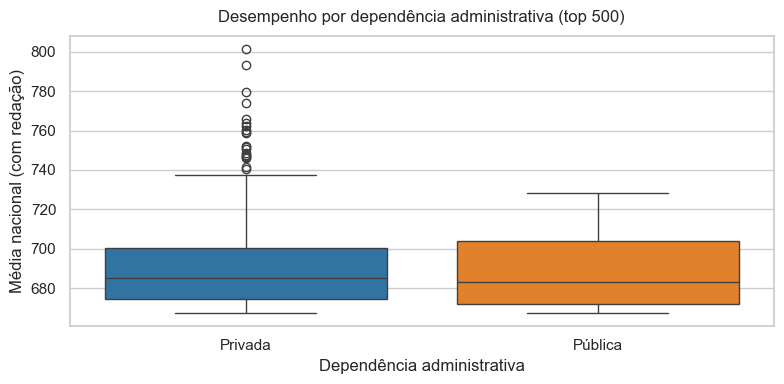

In [18]:
df['Administração'] = df['Administração'].replace({'Público': 'Pública'})

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(
    data=df, 
    x='Administração', 
    y='Média nacional (com redação)', 
    hue='Administração',
    palette=['#1f77b4', '#ff7f0e'], 
    legend=False,
    ax=ax
)

ax.set_title('Desempenho por dependência administrativa (top 500)', fontsize=12, pad=10)
ax.set_xlabel('Dependência administrativa')
ax.set_ylabel('Média nacional (com redação)')

plt.tight_layout()
plt.show()

Analisando a distribuição por dependência administrativa, observa-se que as medianas das escolas públicas e privadas integrantes do top 500 situam-se em patamares muito próximos, em torno de 684 pontos, demonstrando que o corpo principal de ambas as redes dentro deste recorte de elite apresenta rendimento similar. 

Contudo, nota-se uma diferença marcante na dispersão e no teto de desempenho: a rede privada exibe maior amplitude interquartil e concentra a totalidade dos *outliers* de altíssima performance, com médias variando entre 740 e 800 pontos. Em contrapartida, as instituições públicas presentes na amostra, compostas predominantemente por colégios federais e institutos de aplicação, demonstram uma distribuição mais compacta e um teto de notas mais contido, sem registros de pontos atípicos na cauda superior.

Compreendido o impacto da dependência administrativa na dispersão das notas, outro fator estrutural relevante é a escala da instituição. A dimensão da do grupo de participantes pode atuar como um elemento moderador do desempenho médio, uma vez que turmas menores tendem a apresentar menor variabilidade interna, enquanto grupos mais numerosos enfrentam o desafio de manter a homogeneidade do rendimento. 

Para analisar essa dinâmica no recorte das 500 melhores instituições, será plotado um gráfico de dispersão (*scatter plot*) relacionando o `Número de participantes` à `Média nacional (com redação)`, com a diferenciação por dependência administrativa. Essa abordagem permite discutir eventuais efeitos de escala, padrões de estabilização da média e a presença de instituições de altíssimo rendimento em diferentes portes escolares.

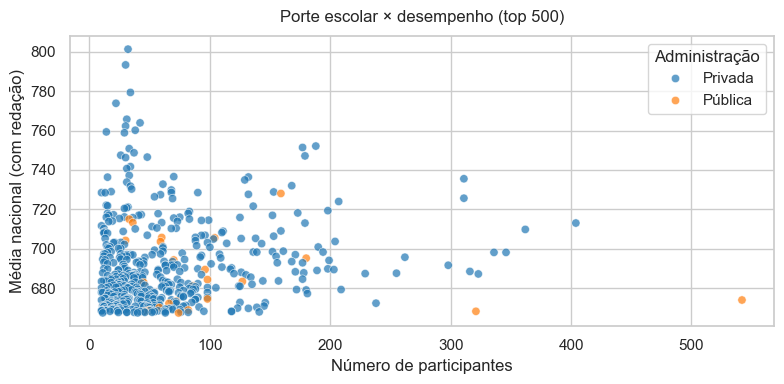

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(
    data=df, 
    x='Número de participantes', 
    y='Média nacional (com redação)', 
    hue='Administração', 
    alpha=0.7, 
    palette=['#1f77b4', '#ff7f0e'], 
    ax=ax
)

ax.set_title('Porte escolar × desempenho (top 500)', fontsize=12, pad=10)
ax.set_xlabel('Número de participantes')
ax.set_ylabel('Média nacional (com redação)')

plt.tight_layout()
plt.show()

A análise de dispersão revela que o desempenho extremo no topo do exame está fortemente associado a instituições de pequeno e médio porte. As pontuações mais elevadas do *dataset*, que ultrapassam o patamar de 740 pontos, concentram-se quase exclusivamente em colégios com turmas reduzidas, variando entre 10 e 50 concluintes inscritos no exame. Conforme a escala do corpo discente se amplia e o número de participantes ultrapassa a marca de 100 alunos, observa-se uma clara convergência das médias para a faixa entre 680 e 720 pontos, evidenciando que em grupos maiores o desempenho tende a se estabilizar devido à maior diversidade no rendimento dos estudantes. Além disso, a sobreposição das categorias administrativas reforça que as poucas instituições públicas do top 500 situam-se majoritariamente no segmento de porte médio a grande, enquanto a rede privada domina tanto os contingentes reduzidos de altíssima performance quanto os grandes colégios de escala.

Após examinar as dimensões de desempenho, dependência administrativa e porte escolar, resta analisar a distribuição territorial dessas instituições no cenário nacional. A localização geográfica é um fator determinante para compreender a concentração de recursos, infraestrutura e redes de ensino de ponta. Para isso, utiliza-se um gráfico para visualizar o volume de escolas presentes no recorte divididas por `Estado`. É indispensável, contudo, pontuar uma ressalva metodológica fundamental: como este *dataset* contempla estritamente um recorte amostral das 500 escolas de maior rendimento do país, e não uma amostragem aleatória ou proporcional de toda a rede de educação básica brasileira, os resultados refletem exclusivamente a representatividade dos estados no topo do exame, não devendo ser extrapolados para inferir a qualidade média do ensino geral de cada Unidade da Federação (UF).

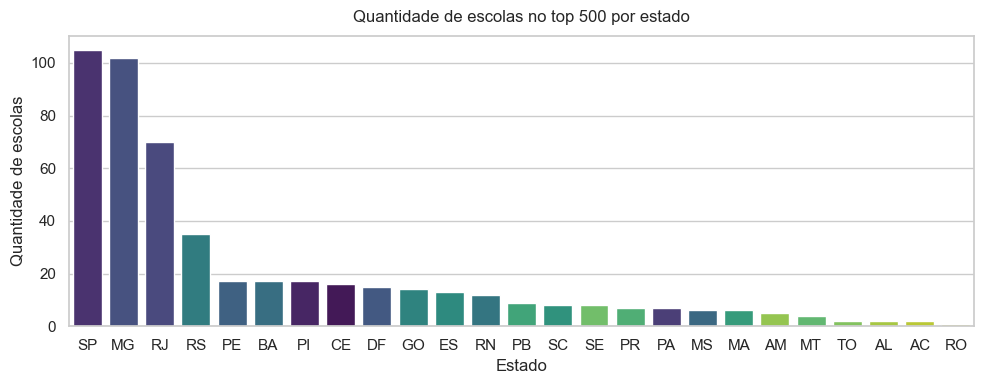

In [49]:
ordem_estados = df['Estado'].value_counts().index

fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(
    data=df, 
    x='Estado', 
    order=ordem_estados, 
    palette='viridis', 
    hue='Estado',
    legend=False,
    ax=ax
)

ax.set_title('Quantidade de escolas no top 500 por estado', fontsize=12, pad=10)
ax.set_xlabel('Estado')
ax.set_ylabel('Quantidade de escolas')

plt.tight_layout()
plt.show()

A análise da distribuição territorial evidencia uma acentuada disparidade regional na presença de instituições no grupo de elite do exame. A Região Sudeste domina expressivamente a amostragem, liderada pelo estado de São Paulo, seguido por Minas Gerais e Rio de Janeiro, que juntos concentram mais da metade de todas as escolas integrantes do top 500. Notam-se também presenças relevantes de estados das regiões Nordeste e Sul, como Ceará e Paraná, sustentados por polos privados de alto desempenho e colégios tradicionais. Esse panorama reflete a centralização de redes educacionais de alta performance e a densidade populacional e socioeconômica dessas regiões, confirmando a relevância de manter a variável de localização como atributo categórico no desenvolvimento do modelo preditivo.

<h2>4- Tratamento e separação dos dados</h2>

Após uma análise exploratória dos dados, é fundamental realizar o tratamento desses dados, no contexto de Aprendizado de Máquina.

Verifica-se que as variáveis `Estado` e `Administração` são categóricas, diferentemente das outras variáveis, que são numéricas. Por esse motivo, será necessário um tratamento dos dados dessas variáveis, uma vez que a maioria dos algoritmos de Aprendizado de Máquina opera através de operações matemáticas e matrizes numéricas, incapazes de processar diretamente valores em texto (*strings*). 

A variável `Administração`, por ser booleana (pública ou privada), pode ser facilmente convertida para 0s e 1s. Adotando 0 como pública e 1 como privada, tem-se:

In [11]:
mapa_bool = {
    'Pública': 0,
    'Público': 0, 
    'Privada': 1
}

df['Administração'] = df['Administração'].map(
    mapa_bool
)

df.head().style.hide(axis = 'index')

ID Escola,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Média nacional (com redação),Administração,Número de participantes,Estado_AL,Estado_AM,Estado_BA,Estado_CE,Estado_DF,Estado_ES,Estado_GO,Estado_MA,Estado_MG,Estado_MS,Estado_MT,Estado_PA,Estado_PB,Estado_PE,Estado_PI,Estado_PR,Estado_RJ,Estado_RN,Estado_RO,Estado_RS,Estado_SC,Estado_SE,Estado_SP,Estado_TO
23246871,1,1,1,1,1,1,774.580000,801.290000,nan,32,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
23246847,2,2,2,2,2,2,765.130000,793.300000,nan,30,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
23246880,3,3,3,3,3,3,753.580000,779.330000,nan,34,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
22144714,1,1,1,1,4,4,743.880000,773.830000,nan,22,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
23235543,4,4,4,4,5,6,737.170000,765.730000,nan,31,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


Diferentemente da dependência administrativa, a variável `Estado` possui natureza categórica nominal sem qualquer relação de ordem implícita entre as regiões. Para evitar que o modelo interprete erroneamente que determinadas siglas possuem peso numérico superior a outras, adota-se o *One-Hot Encoding*, uma técnica que transforma uma variável categórica nominal (como Estado) em várias colunas binárias contendo apenas valores 0 ou 1.

Ou seja, em vez de atribuir números sequenciais para cada estado (o que, por exemplo, poderia fazer o modelo achar que SP tem um "valor" 20 vezes maior que AC), ele cria uma coluna para cada localidade. Assim, se a escola for do Ceará, a coluna Estado_CE recebe 1 e todas as outras colunas de estados recebem 0. O parâmetro drop='first' remove a primeira coluna para evitar redundância matemática (multicolinearidade) no modelo.

In [15]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='first', sparse_output=False)

estados_encoded = encoder.fit_transform(df[['Estado']])

colunas_estados = encoder.get_feature_names_out(['Estado'])
df_estados = pd.DataFrame(estados_encoded, columns=colunas_estados, index=df.index)

df = pd.concat([df.drop(columns=['Estado']), df_estados], axis=1)

df.head().style.hide(axis = 'index')

ID Escola,Escola,Cidade,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Média nacional (com redação),Administração,Número de participantes,Estado_AL,Estado_AM,Estado_BA,Estado_CE,Estado_DF,Estado_ES,Estado_GO,Estado_MA,Estado_MG,Estado_MS,Estado_MT,Estado_PA,Estado_PB,Estado_PE,Estado_PI,Estado_PR,Estado_RJ,Estado_RN,Estado_RO,Estado_RS,Estado_SC,Estado_SE,Estado_SP,Estado_TO
23246871,Ari De Sa Cavalcante - Mario Mamede,Fortaleza,1,1,1,1,1,1,774.580000,801.290000,Privada,32,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
23246847,Farias Brito Colegio De Aplicacao,Fortaleza,2,2,2,2,2,2,765.130000,793.300000,Privada,30,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
23246880,Christus Colegio Pre Universitario,Fortaleza,3,3,3,3,3,3,753.580000,779.330000,Privada,34,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
22144714,Sao Jose Leste,Teresina,1,1,1,1,4,4,743.880000,773.830000,Privada,22,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
23235543,Ari De Sa Cavalcante - Major Facundo,Fortaleza,4,4,4,4,5,6,737.170000,765.730000,Privada,31,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


Tratados os dados, a próxima etapa é separá-los em dois grupos: treino e teste. Os dados de treino são aqueles que o algoritmo utiliza para aprender os padrões e ajustar seus coeficientes internos, enquanto os dados de teste funcionam como uma prova cega, servindo para avaliar a capacidade de generalização do modelo preditivo em dados inéditos e garantir que ele não esteja apenas decorando a amostra (*overfitting*).

O conjunto de treino representará $90\%$ dos dados, enquanto o de teste $10\%$. Será utilizado train_test_split com semente aleatória (SEED = $42$) para garantir a reprodutibilidade do experimento. 

In [12]:
from sklearn.model_selection import train_test_split

indices_treino, indices_teste = train_test_split(
    df.index, test_size=0.1, random_state=42
)

df_treino = df.loc[indices_treino]
df_teste = df.loc[indices_teste]

X_treino = df_treino.reindex(atributos, axis=1)
y_treino = df_treino.reindex(target, axis=1)

X_teste = df_teste.reindex(atributos, axis=1)
y_teste = df_teste.reindex(target, axis=1)

Abaixo, conseguimos conferir os conjuntos de treino dos atributos (X_treino) e do target (y_treino); e de teste dos atributos (X_teste) e do target (y_teste).

In [16]:
X_treino.head().style.hide(axis = 'index')

ID Escola,Estado,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Administração,Número de participantes
33196214,RJ,4,3,13,12,73,78,676.910000,Privada,93
33179999,RJ,7,7,29,30,178,193,654.690000,Privada,45
31205265,MG,1,2,21,43,131,265,646.010000,Privada,61
31346799,MG,2,2,77,77,399,433,633.650000,Privada,27
24089214,RN,7,7,7,7,189,250,647.660000,Privada,70


In [17]:
X_teste.head().style.hide(axis = 'index')

ID Escola,Estado,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Administração,Número de participantes
52034054,GO,8,12,11,15,351,535,628.560000,Privada,78
31260908,MG,1,1,10,12,74,80,676.790000,Privada,19
31239666,MG,1,1,70,73,364,423,634.170000,Privada,30
27220885,AL,1,1,1,1,152,167,657.670000,Privada,155
21273456,MA,1,1,1,1,104,151,660.780000,Privada,13


In [19]:
y_treino.head().style.hide(axis = 'index')

Média nacional (com redação)
714.390000
692.290000
698.770000
671.960000
690.700000


In [18]:
y_teste.head().style.hide(axis = 'index')

Média nacional (com redação)
675.620000
714.070000
674.400000
696.150000
705.240000


<h2>Referências bibliográficas</h2>

1. Enem. Disponível em: <http://www.gov.br/inep/pt-br/areas-de-atuacao/avaliacao-e-exames-educacionais/enem>. Acesso em: 17 ago. 2026.

2. CAPUTO, Gabriela. **Enem: como funciona a TRI Por que duas pessoas com acertos iguais tiram notas**, G1. Disponível em: <https://g1.globo.com/educacao/enem/2025/noticia/2025/11/05/enem-como-funciona-a-tri-por-que-duas-pessoas-com-acertos-iguais-tiram-notas-diferentes.ghtml>. Acesso em: 17 ago. 2026.